# Implied Volatility Solver

This notebook back-solves for **implied volatility** — the volatility that makes the Black-Scholes price equal an observed market price. It implements two root-finding methods, **Newton-Raphson** (fast) with a **Brent's method** fallback (robust), and tests them across the full range of strikes.

## What implied volatility is
Black-Scholes takes volatility as an *input* and produces a price. But in the market we observe the **price** and want to know the volatility the market is implying. That's the inverse problem:

$$\text{Given a market price } C_{\text{mkt}}, \text{ find } \sigma \text{ such that } C_{\text{BS}}(\sigma) = C_{\text{mkt}}$$

There's no closed-form inverse — Black-Scholes can't be algebraically solved for σ. So we solve it **numerically** with root-finding.

## Why two methods
- **Newton-Raphson** uses the derivative (vega) to converge very fast — typically 3-5 iterations. But it can fail: if vega is near zero (deep in/out-of-the-money) or the initial guess is poor, it can diverge.
- **Brent's method** is slower but bracketed and guaranteed to converge as long as the root is enclosed. It's the safety net.

The production-quality solver tries Newton first, falls back to Brent if Newton misbehaves. That's the standard pattern: fast when you can, robust when you must.

In [1]:
import numpy as np
from scipy.stats import norm
from scipy.optimize import brentq
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)

---
# 1. The price and its derivative (vega)

Newton-Raphson needs two things: the function whose root we want, and its derivative.

**The function:** $f(\sigma) = C_{\text{BS}}(\sigma) - C_{\text{mkt}}$. We want $f(\sigma) = 0$.

**Its derivative:** $f'(\sigma) = \dfrac{\partial C_{\text{BS}}}{\partial \sigma} = \text{vega}$. Conveniently, vega has a clean closed form:

$$\text{vega} = S\, N'(d_1)\, \sqrt{T}$$

So each Newton step needs one price evaluation and one vega evaluation — both cheap.

In [2]:
def bs_call_price(S, K, T, r, sigma):
    """Black-Scholes European call price."""
    if sigma <= 0 or T <= 0:
        return max(S - K * np.exp(-r * T), 0.0)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


def bs_vega(S, K, T, r, sigma):
    """Vega = dC/dsigma. The derivative Newton-Raphson needs."""
    if sigma <= 0 or T <= 0:
        return 0.0
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)


# Sanity check.
S, K, T, r, sigma_true = 100, 100, 1.0, 0.05, 0.25
price = bs_call_price(S, K, T, r, sigma_true)
print(f"At sigma={sigma_true}: price={price:.4f}, vega={bs_vega(S,K,T,r,sigma_true):.4f}")

At sigma=0.25: price=12.3360, vega=37.8420


---
# 2. Method 1 — Newton-Raphson

Newton's update rule: from a current guess $\sigma_n$, step to

$$\sigma_{n+1} = \sigma_n - \frac{f(\sigma_n)}{f'(\sigma_n)} = \sigma_n - \frac{C_{\text{BS}}(\sigma_n) - C_{\text{mkt}}}{\text{vega}(\sigma_n)}$$

**Intuition:** the price is too high by some amount; divide that error by how fast price changes with vol (vega) to get how much to adjust vol. Repeat until the price matches.

**The good:** quadratic convergence — the number of correct digits roughly doubles each step. Usually 3-5 iterations.

**The failure modes we guard against:**
- **Vega near zero** → division blows up. Deep ITM/OTM options have tiny vega.
- **Negative volatility** → we clamp to stay positive.
- **Non-convergence** → cap the iterations and signal failure so the caller can fall back.

In [3]:
def implied_vol_newton(price, S, K, T, r, sigma0=0.2, tol=1e-8, max_iter=50):
    """Newton-Raphson implied vol. Returns (sigma, converged)."""
    sigma = sigma0
    for i in range(max_iter):
        diff = bs_call_price(S, K, T, r, sigma) - price   # f(sigma)
        if abs(diff) < tol:
            return sigma, True
        vega = bs_vega(S, K, T, r, sigma)                 # f'(sigma)
        if vega < 1e-10:           # vega too small -> Newton unsafe
            return sigma, False
        sigma = sigma - diff / vega                       # Newton step
        if sigma <= 0:             # keep vol positive
            sigma = tol
    return sigma, False            # hit max_iter without converging


# Recover the known vol from its price.
recovered, ok = implied_vol_newton(price, S, K, T, r)
print(f"True sigma:      {sigma_true}")
print(f"Recovered (NR):  {recovered:.8f}  (converged={ok})")

True sigma:      0.25
Recovered (NR):  0.25000000  (converged=True)


---
# 3. Method 2 — Brent's method (the robust fallback)

Brent's method doesn't use the derivative. Instead it **brackets** the root in an interval $[\sigma_{\text{lo}}, \sigma_{\text{hi}}]$ where the function changes sign, then narrows the bracket — combining bisection (safe but slow) with inverse quadratic interpolation (fast). As long as the root is inside the bracket, it **cannot** fail to converge.

The tradeoff vs Newton: slower (no derivative information), but guaranteed. We use a wide bracket — volatility between 0.01% and 500% — which covers any realistic option.

In [4]:
def implied_vol_brent(price, S, K, T, r, lo=1e-4, hi=5.0):
    """Brent's method implied vol. Returns (sigma, converged)."""
    # The root must be bracketed: f(lo) and f(hi) must have opposite signs.
    intrinsic = max(S - K * np.exp(-r * T), 0.0)
    if price < intrinsic - 1e-10 or price < 0:
        return np.nan, False        # price below intrinsic -> no solution
    try:
        sigma = brentq(lambda s: bs_call_price(S, K, T, r, s) - price,
                       lo, hi, xtol=1e-10, maxiter=200)
        return sigma, True
    except (ValueError, RuntimeError):
        return np.nan, False


recovered_b, ok_b = implied_vol_brent(price, S, K, T, r)
print(f"Recovered (Brent): {recovered_b:.8f}  (converged={ok_b})")

Recovered (Brent): 0.25000000  (converged=True)


---
# 4. The production solver: Newton first, Brent fallback

The robust pattern: try the fast method, and if it fails to converge, fall back to the guaranteed one. This gives Newton's speed in the common case and Brent's reliability in the hard cases (deep in/out-of-the-money, where vega is tiny and Newton struggles).

In [5]:
def implied_vol(price, S, K, T, r):
    """Newton-Raphson with Brent fallback. Returns (sigma, method)."""
    sigma, ok = implied_vol_newton(price, S, K, T, r)
    if ok:
        return sigma, "newton"
    sigma, ok = implied_vol_brent(price, S, K, T, r)
    if ok:
        return sigma, "brent"
    return np.nan, "failed"


sigma, method = implied_vol(price, S, K, T, r)
print(f"Combined solver: sigma={sigma:.8f} via {method}")

Combined solver: sigma=0.25000000 via newton


---
# 5. Round-trip test across the smile

The key validation: take a range of strikes, price each with a *known* volatility, then solve for implied vol and confirm we recover the original. If the solver is correct, recovered vol should match the input to high precision across **all** strikes — including the deep in/out-of-the-money ones where Newton alone would struggle.

To make it realistic, we use a volatility that *varies* with strike (a synthetic smile), so we're testing the solver across different true vols, not just one.

In [6]:
strikes = np.linspace(70, 130, 25)

# Synthetic smile: higher vol at the wings (like a real market skew).
def true_vol(K):
    return 0.20 + 0.0008 * (K - 100)**2 / 100

# For each strike: price with the true vol, then solve back for implied vol.
records = []
for K in strikes:
    sig_true = true_vol(K)
    px = bs_call_price(S, K, T, r, sig_true)
    sig_implied, method = implied_vol(px, S, K, T, r)
    records.append({
        "strike": K, "true_vol": sig_true, "implied_vol": sig_implied,
        "error": abs(sig_implied - sig_true), "method": method,
    })

import pandas as pd
df = pd.DataFrame(records)
print(f"Max recovery error across all strikes: {df['error'].max():.2e}")
print(f"Methods used: {df['method'].value_counts().to_dict()}")
print()
print(df[["strike", "true_vol", "implied_vol", "error", "method"]].iloc[::4].round(6).to_string(index=False))

Max recovery error across all strikes: 2.21e-10
Methods used: {'newton': 25}

 strike  true_vol  implied_vol  error method
   70.0    0.2072       0.2072    0.0 newton
   80.0    0.2032       0.2032    0.0 newton
   90.0    0.2008       0.2008    0.0 newton
  100.0    0.2000       0.2000    0.0 newton
  110.0    0.2008       0.2008    0.0 newton
  120.0    0.2032       0.2032    0.0 newton
  130.0    0.2072       0.2072    0.0 newton


### Plot: recovered smile vs the true smile

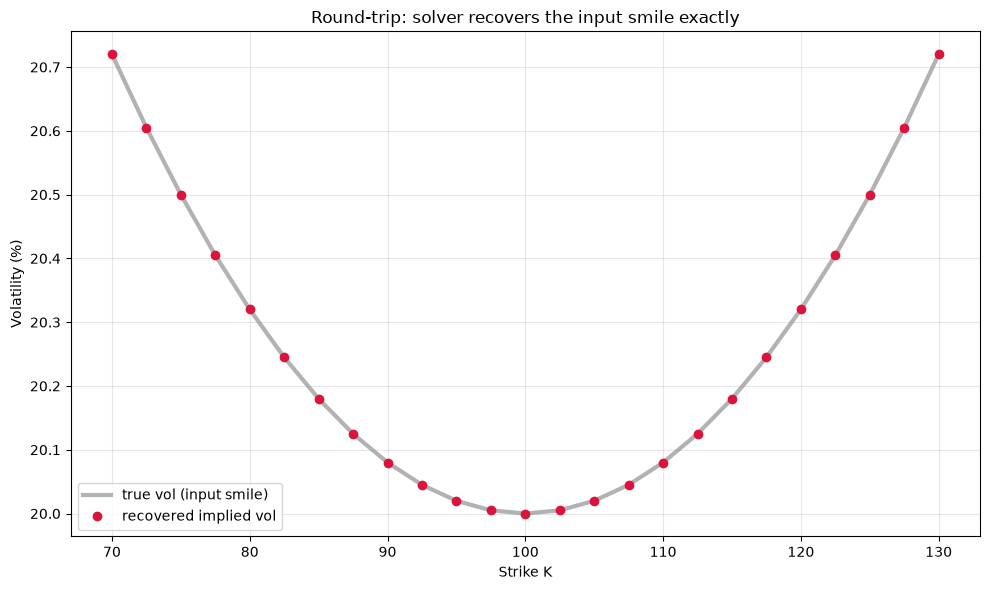

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(strikes, df["true_vol"] * 100, "-", color="gray", lw=3,
        label="true vol (input smile)", alpha=0.6)
ax.plot(strikes, df["implied_vol"] * 100, "o", color="crimson",
        label="recovered implied vol", markersize=6)
ax.set_xlabel("Strike K"); ax.set_ylabel("Volatility (%)")
ax.set_title("Round-trip: solver recovers the input smile exactly")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

---
# 6. How fast does Newton converge?

Newton's quadratic convergence means the error shrinks dramatically each iteration. Let's watch it for a single option — the number of correct digits roughly doubles per step.

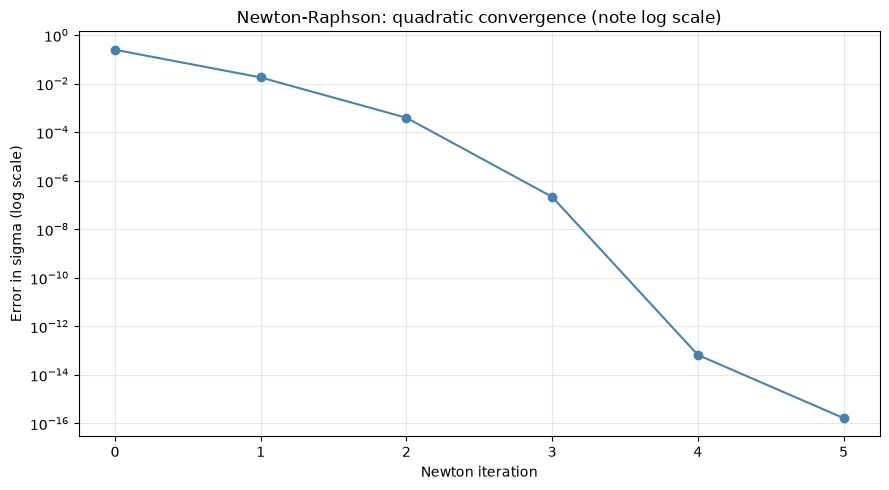

Error per iteration:
  iter 0: 2.50e-01
  iter 1: 1.81e-02
  iter 2: 3.93e-04
  iter 3: 2.17e-07
  iter 4: 6.64e-14
  iter 5: 1.67e-16


In [8]:
def newton_trace(price, S, K, T, r, sigma0=0.5, true_sigma=0.25, max_iter=10):
    """Run Newton and record the error at each iteration."""
    sigma = sigma0
    errors = [abs(sigma - true_sigma)]
    for _ in range(max_iter):
        diff = bs_call_price(S, K, T, r, sigma) - price
        vega = bs_vega(S, K, T, r, sigma)
        if vega < 1e-10 or abs(diff) < 1e-12:
            break
        sigma = sigma - diff / vega
        errors.append(abs(sigma - true_sigma))
    return errors


px = bs_call_price(S, K, T, r, 0.25)
errors = newton_trace(px, S, K, T, r, sigma0=0.5, true_sigma=0.25)

fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogy(range(len(errors)), errors, "o-", color="steelblue")
ax.set_xlabel("Newton iteration"); ax.set_ylabel("Error in sigma (log scale)")
ax.set_title("Newton-Raphson: quadratic convergence (note log scale)")
ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

print("Error per iteration:")
for i, e in enumerate(errors):
    print(f"  iter {i}: {e:.2e}")